# Structural Analysis of Caspase-Active Compounds

**Section 1** — Behavior patterns across 14 cell lines (fully tested set)  
**Section 2** — HepG2 active compounds: find representative structures per cluster

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, rdFingerprintGenerator
from sklearn.cluster import DBSCAN
import umap
import warnings
warnings.filterwarnings('ignore')

BASE = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/'
gen  = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def to_fp_matrix(mols):
    fps = [gen.GetFingerprint(m) for m in mols]
    return fps, np.array([list(fp.ToBitString()) for fp in fps], dtype=np.float32)

def plot_umap(fp_matrix, labels, title='UMAP', color_map=None, annotate=None):
    """Reusable UMAP — pass any fp_matrix + labels, returns embedding."""
    reducer = umap.UMAP(n_neighbors=min(15, len(fp_matrix)-1),
                        min_dist=0.3, metric='jaccard', random_state=42)
    emb = reducer.fit_transform(fp_matrix)
    unique = list(dict.fromkeys(labels))
    if color_map is None:
        color_map = {l: plt.cm.tab10(i % 10) for i, l in enumerate(unique)}
    fig, ax = plt.subplots(figsize=(8, 6))
    for lbl in unique:
        mask = np.array([l == lbl for l in labels])
        ax.scatter(emb[mask, 0], emb[mask, 1], c=[color_map[lbl]],
                   label=lbl, s=80, edgecolors='black', linewidths=0.5, alpha=0.85)
    if annotate is not None:
        for i, txt in enumerate(annotate):
            ax.annotate(str(txt), (emb[i,0], emb[i,1]),
                        textcoords='offset points', xytext=(4,3), fontsize=6.5, color='#444')
    ax.legend(loc='upper left', fontsize=8.5, framealpha=0.9)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout(); plt.show()
    return emb

print('Ready.')

Ready.


---
## Section 1 — Behavior Patterns Across 14 Cell Lines

only the **1,272 fully-tested compounds** (all 14 cell line results present).  
define 4 behavior groups, compute fingerprints, and plot chemical space.

| A — Pan-toxic | Active in ≥ 5 cell lines |
| B — Jurkat-only | Active ONLY in Jurkat |
| C — HepG2-only | Active ONLY in HepG2 |
| D — HUV-EC-C avoiders | Active in ≥ 3 lines but Inactive in HUV-EC-C |

70 compounds | {'C': 27, 'B': 21, 'A': 13, 'D': 9}


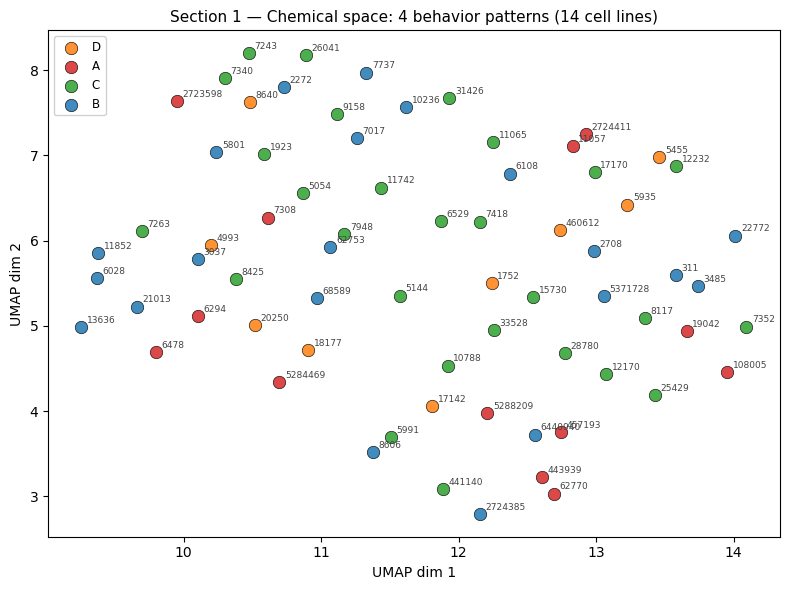

In [45]:
df = pd.read_csv(BASE + 'results/all_cell_line_comparisions/consistent_compounds_caspase_all.csv')
ASSAY_COLS = [c for c in df.columns if c not in ('PUBCHEM_CID', 'pattern', 'behavior')]

smi1 = pd.read_csv(BASE + 'cleaned_datasets/combined_hepg2_casepase.csv',
                   usecols=['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES'])
smi2 = pd.read_csv(BASE + 'cleaned_datasets/AID_1346980_cleaned.csv',
                   usecols=['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES'])
smiles_df = (pd.concat([smi1, smi2])
               .dropna(subset=['PUBCHEM_EXT_DATASOURCE_SMILES'])
               .drop_duplicates('PUBCHEM_CID'))

all14 = df[df[ASSAY_COLS].notna().all(axis=1)].copy()
all14['n_active'] = (all14[ASSAY_COLS] == 'Active').sum(axis=1)

pat_defs = {
    'A — Pan-toxic':         all14[all14['n_active'] >= 5],
    'B — Jurkat-only':       all14[(all14['n_active'] == 1) & (all14['AID_655'] == 'Active')],
    'C — HepG2-only':        all14[(all14['n_active'] == 1) & (all14['combined_hepg2_casepase.csv'] == 'Active')],
    'D — HUV-EC-C avoiders': all14[(all14['n_active'] >= 3) & (all14['AID_656'] == 'Inactive')],
}

# A takes priority for A∩D overlaps
label_map = {}
for name in reversed(list(pat_defs)):
    for cid in pat_defs[name]['PUBCHEM_CID']:
        label_map[cid] = name[0]   # letter only: A/B/C/D

fp_df = (pd.DataFrame({'PUBCHEM_CID': list(label_map)})
           .merge(smiles_df, on='PUBCHEM_CID', how='left'))
fp_df['mol'] = fp_df['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
    lambda s: Chem.MolFromSmiles(s) if pd.notna(s) else None)
fp_df = fp_df[fp_df['mol'].notna()].reset_index(drop=True)
fp_df['label'] = fp_df['PUBCHEM_CID'].map(label_map)
_, fp_matrix_1 = to_fp_matrix(fp_df['mol'].tolist())

print(f'{len(fp_df)} compounds | {fp_df["label"].value_counts().to_dict()}')

emb_1 = plot_umap(
    fp_matrix_1,
    labels    = fp_df['label'].tolist(),
    title     = 'Section 1 — Chemical space: 4 behavior patterns (14 cell lines)',
    color_map = {'A': '#d62728', 'B': '#1f77b4', 'C': '#2ca02c', 'D': '#ff7f0e'},
    annotate  = fp_df['PUBCHEM_CID'].astype(int),
)

---
## Section 2 — HepG2 Active Compounds: Find Representative Structures

Load all **241 HepG2 active** compounds, cluster by structure (DBSCAN on UMAP),  
then show one representative compound per cluster with its real name.
caspase active and mito inactive


241 active HepG2 compounds


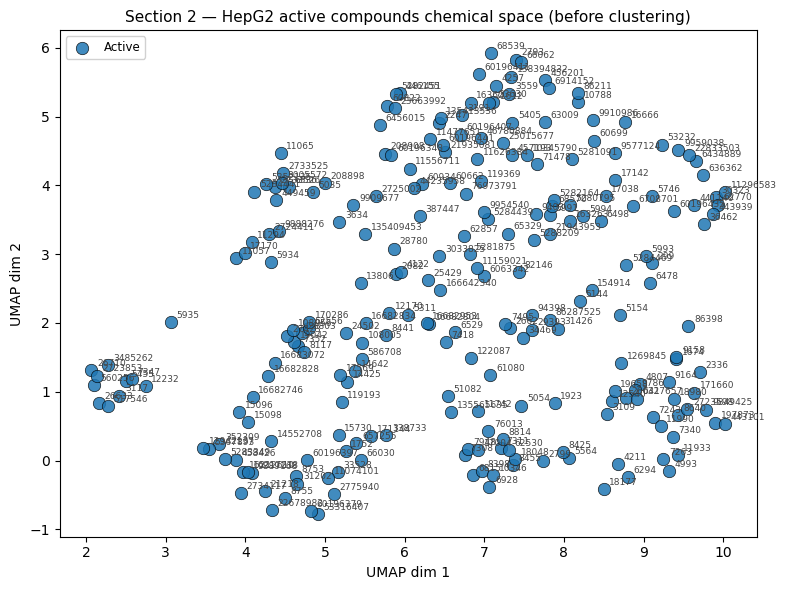

DBSCAN: 14 clusters, 13 noise points


In [46]:
hepg2 = pd.read_csv(BASE + 'cleaned_datasets/combined_hepg2_casepase.csv',
                    usecols=['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES','PUBCHEM_ACTIVITY_OUTCOME'],
                    low_memory=False)
h = (hepg2[hepg2['PUBCHEM_ACTIVITY_OUTCOME'] == 'Active']
       .dropna(subset=['PUBCHEM_EXT_DATASOURCE_SMILES'])
       .reset_index(drop=True))
h['mol'] = h['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
    lambda s: Chem.MolFromSmiles(s) if pd.notna(s) else None)
h = h[h['mol'].notna()].reset_index(drop=True)
h['fp'], fp_matrix_2 = to_fp_matrix(h['mol'].tolist())

print(f'{len(h)} active HepG2 compounds')

# UMAP + DBSCAN
emb_2 = plot_umap(
    fp_matrix_2,
    labels  = ['Active'] * len(h),
    title   = 'Section 2 — HepG2 active compounds chemical space (before clustering)',
    annotate= h['PUBCHEM_CID'].astype(int),
)
h['umap_x'], h['umap_y'] = emb_2[:, 0], emb_2[:, 1]

db = DBSCAN(eps=0.4, min_samples=3).fit(emb_2)
h['cluster'] = db.labels_
n_cl = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
print(f'DBSCAN: {n_cl} clusters, {(db.labels_==-1).sum()} noise points')

Fetching names from PubChem (one per cluster)...
  Cluster  0 (n=  4)  Technical chlordane  [CID 5993]
  Cluster  1 (n= 25)  O-PHENYLENEDIAMINE  [CID 7243]
  Cluster  2 (n= 26)  p-Nonylphenol  [CID 1752]
  Cluster  3 (n= 79)  ebastine  [CID 3191]
  Cluster  4 (n=  7)  Prodiamine  [CID 34469]
  Cluster  5 (n= 19)  Antioxidant No. 33  [CID 7311]
  Cluster  6 (n= 10)  CAS-137-30-4  [CID 3485262]
  Cluster  7 (n=  4)  SR271425  [CID 9909677]
  Cluster  8 (n= 10)  tamoxifen  [CID 2733526]
  Cluster  9 (n= 17)  Octyl 4-hydroxybenzoate  [CID 14642]
  Cluster 10 (n=  6)  MALACHITE GREEN  [CID 11294]
  Cluster 11 (n=  3)  p,p'-DDD  [CID 6294]
  Cluster 12 (n= 13)  Pentaerythritol tetraacrylate  [CID 62556]
  Cluster 13 (n=  5)  Pitavastatin calcium  [CID 5282451]


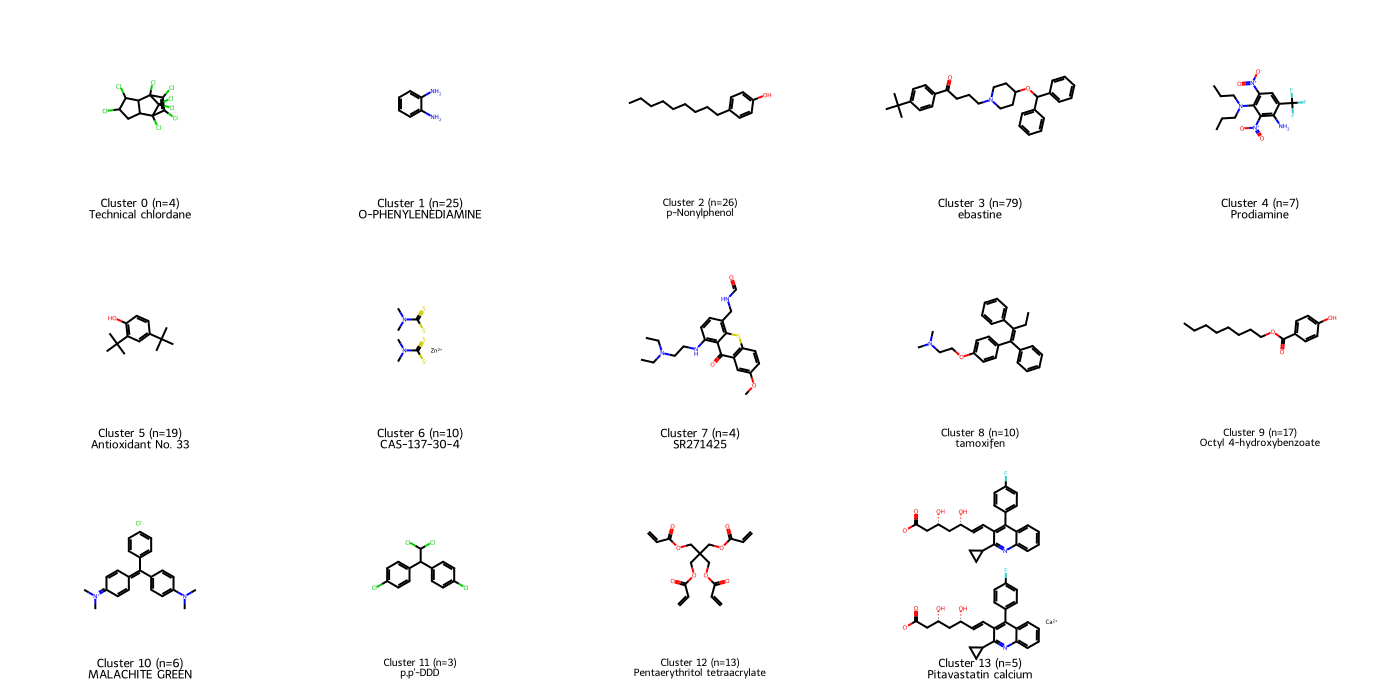

In [47]:
import pubchempy as pcp

def get_name(cid):
    try:
        c = pcp.Compound.from_cid(int(cid))
        syns = c.synonyms or []
        short = [s for s in syns if len(s) <= 30 and s[0].isalpha()]
        return short[0] if short else (syns[0][:28] if syns else str(cid))
    except Exception:
        return str(cid)

# Pick most central compound per cluster, look up its name
reps, legs = [], []
cl_name_map_h = {}   # <-- Section 2 name map (keyed by cluster ID)
print('Fetching names from PubChem (one per cluster)...')

for cl in sorted(h['cluster'].unique()):
    if cl == -1:
        continue
    sub  = h[h['cluster'] == cl].reset_index(drop=True)
    fps  = sub['fp'].tolist()
    avg  = [sum(DataStructs.BulkTanimotoSimilarity(fp, fps)) for fp in fps]
    rep  = sub.loc[int(np.argmax(avg))]
    cid  = int(rep['PUBCHEM_CID'])
    name = get_name(cid)
    reps.append(rep['mol'])
    legs.append(f'Cluster {cl} (n={len(sub)})\n{name}')
    cl_name_map_h[cl] = name   # <-- store by actual cluster ID
    print(f'  Cluster {cl:2d} (n={len(sub):3d})  {name}  [CID {cid}]')

img = Draw.MolsToGridImage(reps, molsPerRow=5, subImgSize=(280, 230),
                           legends=legs, returnPNG=False)
from IPython.display import display
display(img)


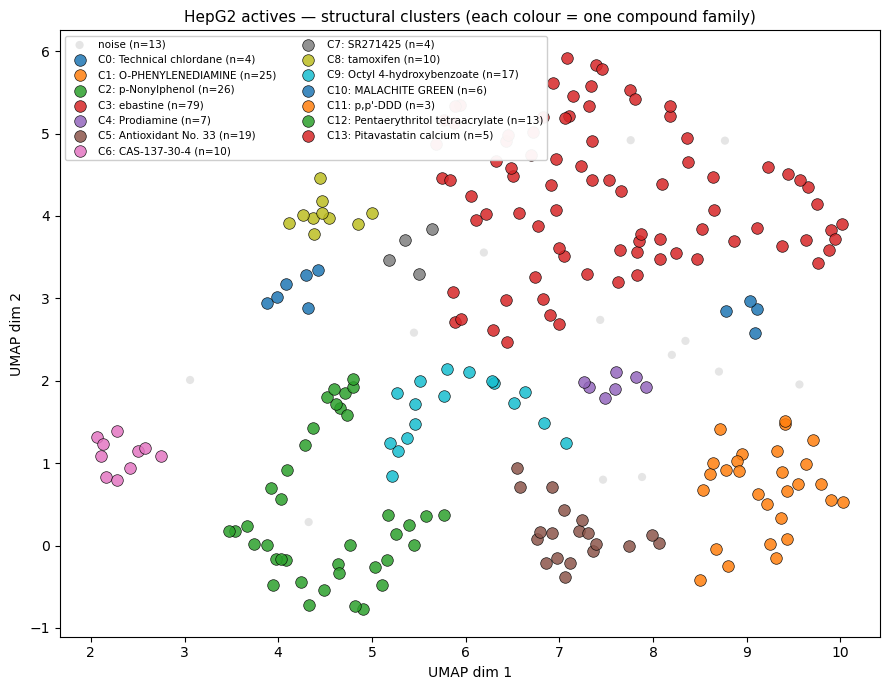

In [48]:
# UMAP re-coloured by cluster
fig, ax = plt.subplots(figsize=(9, 7))
cmap = plt.cm.tab10

noise = h[h['cluster'] == -1]
ax.scatter(noise['umap_x'], noise['umap_y'], c='#cccccc',
           s=35, edgecolors='none', alpha=0.5, label=f'noise (n={len(noise)})')

for cl in sorted(h['cluster'].unique()):
    if cl == -1: continue
    sub  = h[h['cluster'] == cl]
    name = legs[cl].split('\n')[1] if cl < len(legs) else f'Cluster {cl}'
    ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 10)],
               s=70, edgecolors='black', linewidths=0.5, alpha=0.85,
               label=f'C{cl}: {name} (n={len(sub)})')

ax.legend(loc='upper left', fontsize=7.5, framealpha=0.95, ncol=2)
ax.set_title('HepG2 actives — structural clusters (each colour = one compound family)', fontsize=11)
ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
plt.tight_layout()
plt.show()

---
## Section 3 — 27 Compounds Active ONLY in HepG2 (Across All 14 Cell Lines)

These 27 compounds were tested in **all 14 cell lines** and active in **HepG2 only** — nowhere else.  
Do they share a common structure, or are they structurally diverse?

27 compounds with valid SMILES (out of 27)
DBSCAN: 1 clusters, 25 noise (unique structures)

Fetching names from PubChem...
  Cluster 0: n=2 | resorcinol [CID 5054]


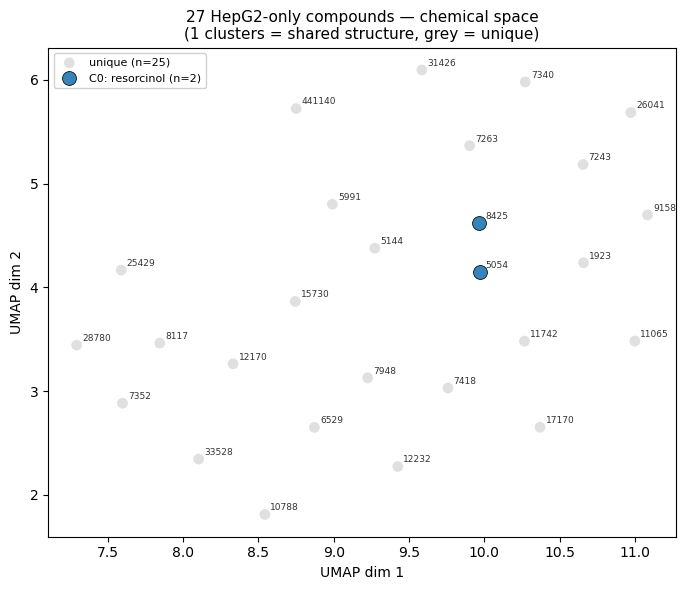


All 27 HepG2-selective compounds:


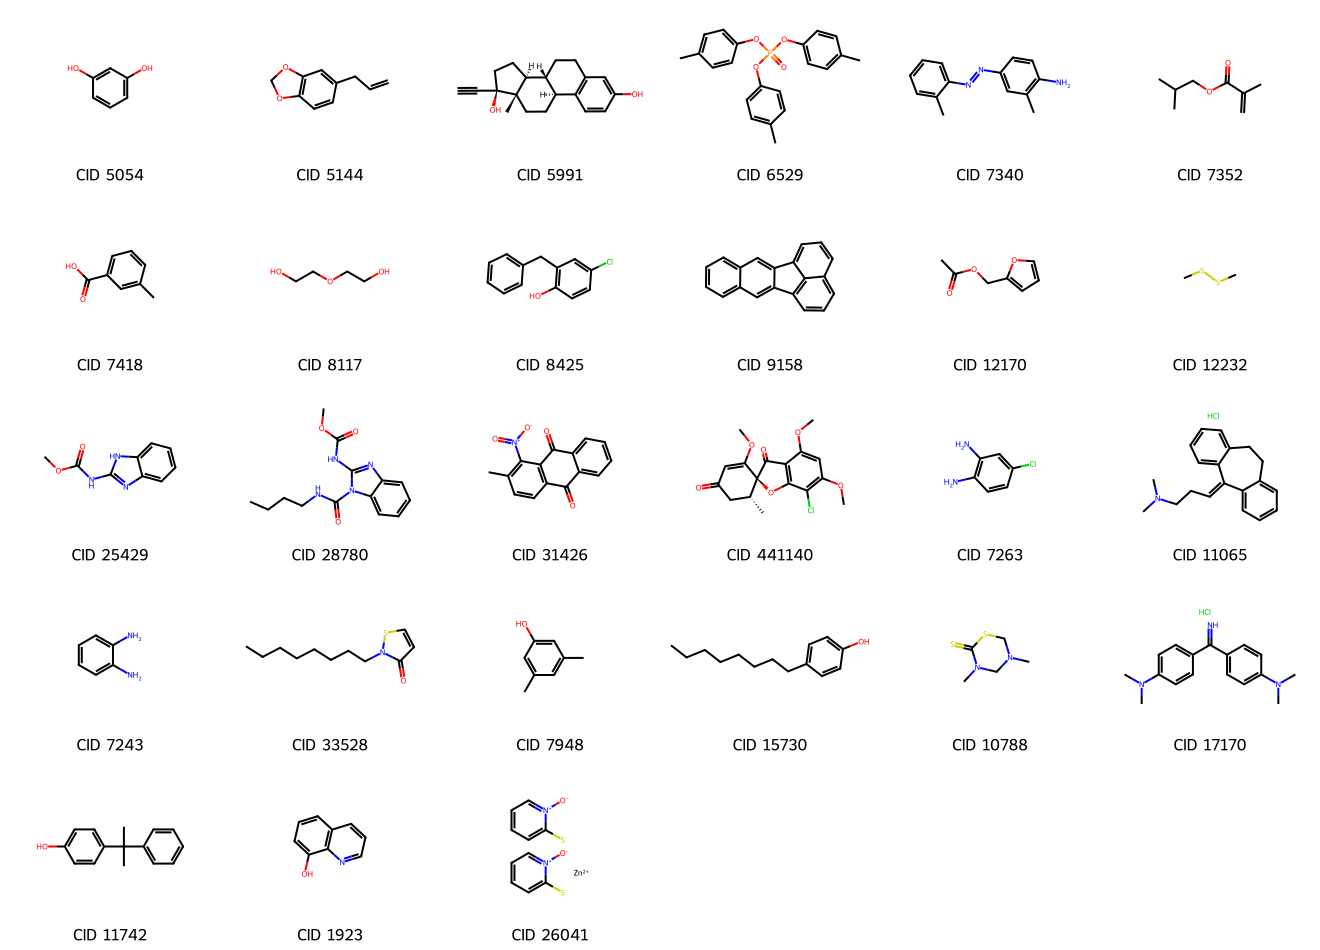


Representative per cluster (1 structural families):


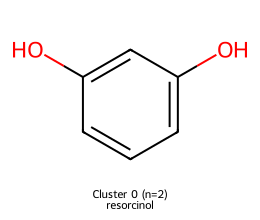

In [49]:
import pubchempy as pcp
from rdkit.Chem import Draw
from IPython.display import display

# Load the 27 HepG2-selective compounds
hepg2_only = pd.read_csv(BASE + 'results/all_cell_line_comparisions/only_hepg2_active.csv')

# Merge SMILES
h27 = hepg2_only[['PUBCHEM_CID']].merge(smiles_df, on='PUBCHEM_CID', how='left')
h27['mol'] = h27['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
    lambda s: Chem.MolFromSmiles(s) if pd.notna(s) else None)
h27 = h27[h27['mol'].notna()].reset_index(drop=True)
h27['fp'], fp_matrix_3 = to_fp_matrix(h27['mol'].tolist())

print(f'{len(h27)} compounds with valid SMILES (out of 27)')

# UMAP — with only 27 points, use small n_neighbors
reducer = umap.UMAP(n_neighbors=min(8, len(h27)-1),
                    min_dist=0.3, metric='jaccard', random_state=42)
emb_3 = reducer.fit_transform(fp_matrix_3)
h27['umap_x'], h27['umap_y'] = emb_3[:, 0], emb_3[:, 1]

# DBSCAN
db27 = DBSCAN(eps=0.5, min_samples=2).fit(emb_3)
h27['cluster'] = db27.labels_
n_cl27 = len(set(db27.labels_)) - (1 if -1 in db27.labels_ else 0)
print(f'DBSCAN: {n_cl27} clusters, {(db27.labels_==-1).sum()} noise (unique structures)')

# Get name + rep per cluster
reps27, legs27 = [], []
print('\nFetching names from PubChem...')
for cl in sorted(h27['cluster'].unique()):
    if cl == -1:
        continue
    sub  = h27[h27['cluster'] == cl].reset_index(drop=True)
    fps  = sub['fp'].tolist()
    avg  = [sum(DataStructs.BulkTanimotoSimilarity(fp, fps)) for fp in fps]
    rep  = sub.loc[int(np.argmax(avg))]
    cid  = int(rep['PUBCHEM_CID'])
    try:
        c    = pcp.Compound.from_cid(cid)
        syns = c.synonyms or []
        short = [s for s in syns if len(s) <= 30 and s[0].isalpha()]
        name = short[0] if short else (syns[0][:28] if syns else str(cid))
    except Exception:
        name = str(cid)
    reps27.append(rep['mol'])
    legs27.append(f'Cluster {cl} (n={len(sub)})\n{name}')
    print(f'  Cluster {cl}: n={len(sub)} | {name} [CID {cid}]')

# Also show all 27 individually (small enough to draw all)
all_mols = h27['mol'].tolist()
all_cids = h27['PUBCHEM_CID'].astype(int).tolist()

# UMAP plot coloured by cluster
fig, ax = plt.subplots(figsize=(7, 6))
cmap = plt.cm.tab10
noise27 = h27[h27['cluster'] == -1]
ax.scatter(noise27['umap_x'], noise27['umap_y'], c='#cccccc',
           s=60, edgecolors='none', alpha=0.6, label=f'unique (n={len(noise27)})')
cl_name_map = {cl: leg.split(chr(10))[1] for cl, leg in zip(sorted(c for c in h27['cluster'].unique() if c != -1), legs27)}
for cl in sorted(h27['cluster'].unique()):
    if cl == -1: continue
    sub = h27[h27['cluster'] == cl]
    ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 10)],
               s=100, edgecolors='black', linewidths=0.6, alpha=0.9,
               label=f'C{cl}: {cl_name_map.get(cl, f"Cluster {cl}")} (n={len(sub)})')
for i, row in h27.iterrows():
    ax.annotate(str(int(row['PUBCHEM_CID'])), (row['umap_x'], row['umap_y']),
                textcoords='offset points', xytext=(4, 3), fontsize=6.5, color='#333')
ax.legend(loc='upper left', fontsize=8, framealpha=0.9)
ax.set_title(f'27 HepG2-only compounds — chemical space\n({n_cl27} clusters = shared structure, grey = unique)', fontsize=11)
ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
plt.tight_layout()
plt.show()

# Draw all 27 structures
print('\nAll 27 HepG2-selective compounds:')
img_all = Draw.MolsToGridImage(
    all_mols, molsPerRow=6, subImgSize=(220, 190),
    legends=[f'CID {c}' for c in all_cids],
    returnPNG=False)
display(img_all)

# Draw cluster reps (if any clusters found)
if reps27:
    print(f'\nRepresentative per cluster ({n_cl27} structural families):')
    img_reps = Draw.MolsToGridImage(
        reps27, molsPerRow=min(5, len(reps27)), subImgSize=(260, 220),
        legends=legs27, returnPNG=False)
    display(img_reps)
else:
    print('\nNo structural clusters found — all 27 compounds are structurally unique.')

---
## Section 4 — Caspase AND Mito Active Compounds

288 compounds that activate **both caspase-3/7 AND mitochondrial stress** in HepG2.  
Clustering shows which structural families drive this dual activation.

288 caspase+mito active compounds


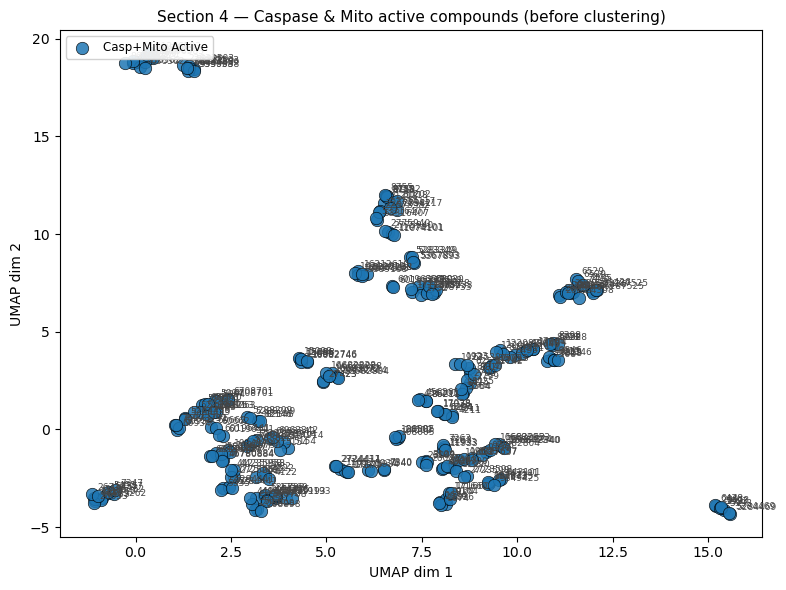

DBSCAN: 38 clusters, 2 noise


In [50]:
import pubchempy as pcp
from rdkit.Chem import Draw
from IPython.display import display

# Load
cm = pd.read_csv(BASE + 'results/casepase_mito_comparisons/caspase_and_mito_Active.csv',
                 usecols=['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES'], low_memory=False)
cm['mol'] = cm['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
    lambda s: Chem.MolFromSmiles(s) if pd.notna(s) else None)
cm = cm[cm['mol'].notna()].reset_index(drop=True)
cm['fp'], fp_matrix_4 = to_fp_matrix(cm['mol'].tolist())
print(f'{len(cm)} caspase+mito active compounds')

# UMAP + DBSCAN
emb_4 = plot_umap(fp_matrix_4, labels=['Casp+Mito Active'] * len(cm),
                  title='Section 4 — Caspase & Mito active compounds (before clustering)',
                  annotate=cm['PUBCHEM_CID'].astype(int))
cm['umap_x'], cm['umap_y'] = emb_4[:, 0], emb_4[:, 1]

db_cm = DBSCAN(eps=0.4, min_samples=3).fit(emb_4)
cm['cluster'] = db_cm.labels_
n_cl_cm = len(set(db_cm.labels_)) - (1 if -1 in db_cm.labels_ else 0)
print(f'DBSCAN: {n_cl_cm} clusters, {(db_cm.labels_==-1).sum()} noise')

Fetching names from PubChem...
  Cluster  0 (n=  8)  Technical chlordane  [CID 5993]
  Cluster  1 (n=  8)  Dibenz[a,c]anthracene  [CID 9164]
  Cluster  2 (n= 12)  p-Nonylphenol  [CID 1752]
  Cluster  3 (n= 12)  clofoctol  [CID 2799]
  Cluster  4 (n=  4)  albendazole  [CID 2082]
  Cluster  5 (n=  8)  Prodiamine  [CID 34469]
  Cluster  6 (n=  4)  dipyrithione  [CID 3109]
  Cluster  7 (n= 12)  CAS-137-30-4  [CID 3485262]
  Cluster  8 (n=  6)  p,p'-DDD  [CID 6294]
  Cluster  9 (n=  8)  USAF EK-678  [CID 11990]
  Cluster 10 (n= 16)  Octyl 4-hydroxybenzoate  [CID 14642]
  Cluster 11 (n= 10)  Sodium aristolochate  [CID 154914]
  Cluster 12 (n=  4)  Mechlorethamine hydrochloride  [CID 5935]
  Cluster 13 (n= 20)  estradiol cypionate  [CID 9403]
  Cluster 14 (n=  8)  para-nitrophenetol  [CID 7495]
  Cluster 15 (n=  6)  Di-tert-butyl-m-cresol  [CID 10346]
  Cluster 16 (n=  4)  Antioxidant 425  [CID 6928]
  Cluster 17 (n=  4)  Ursol Olive 6G  [CID 7263]
  Cluster 18 (n= 10)  Antioxidant No. 33  [C

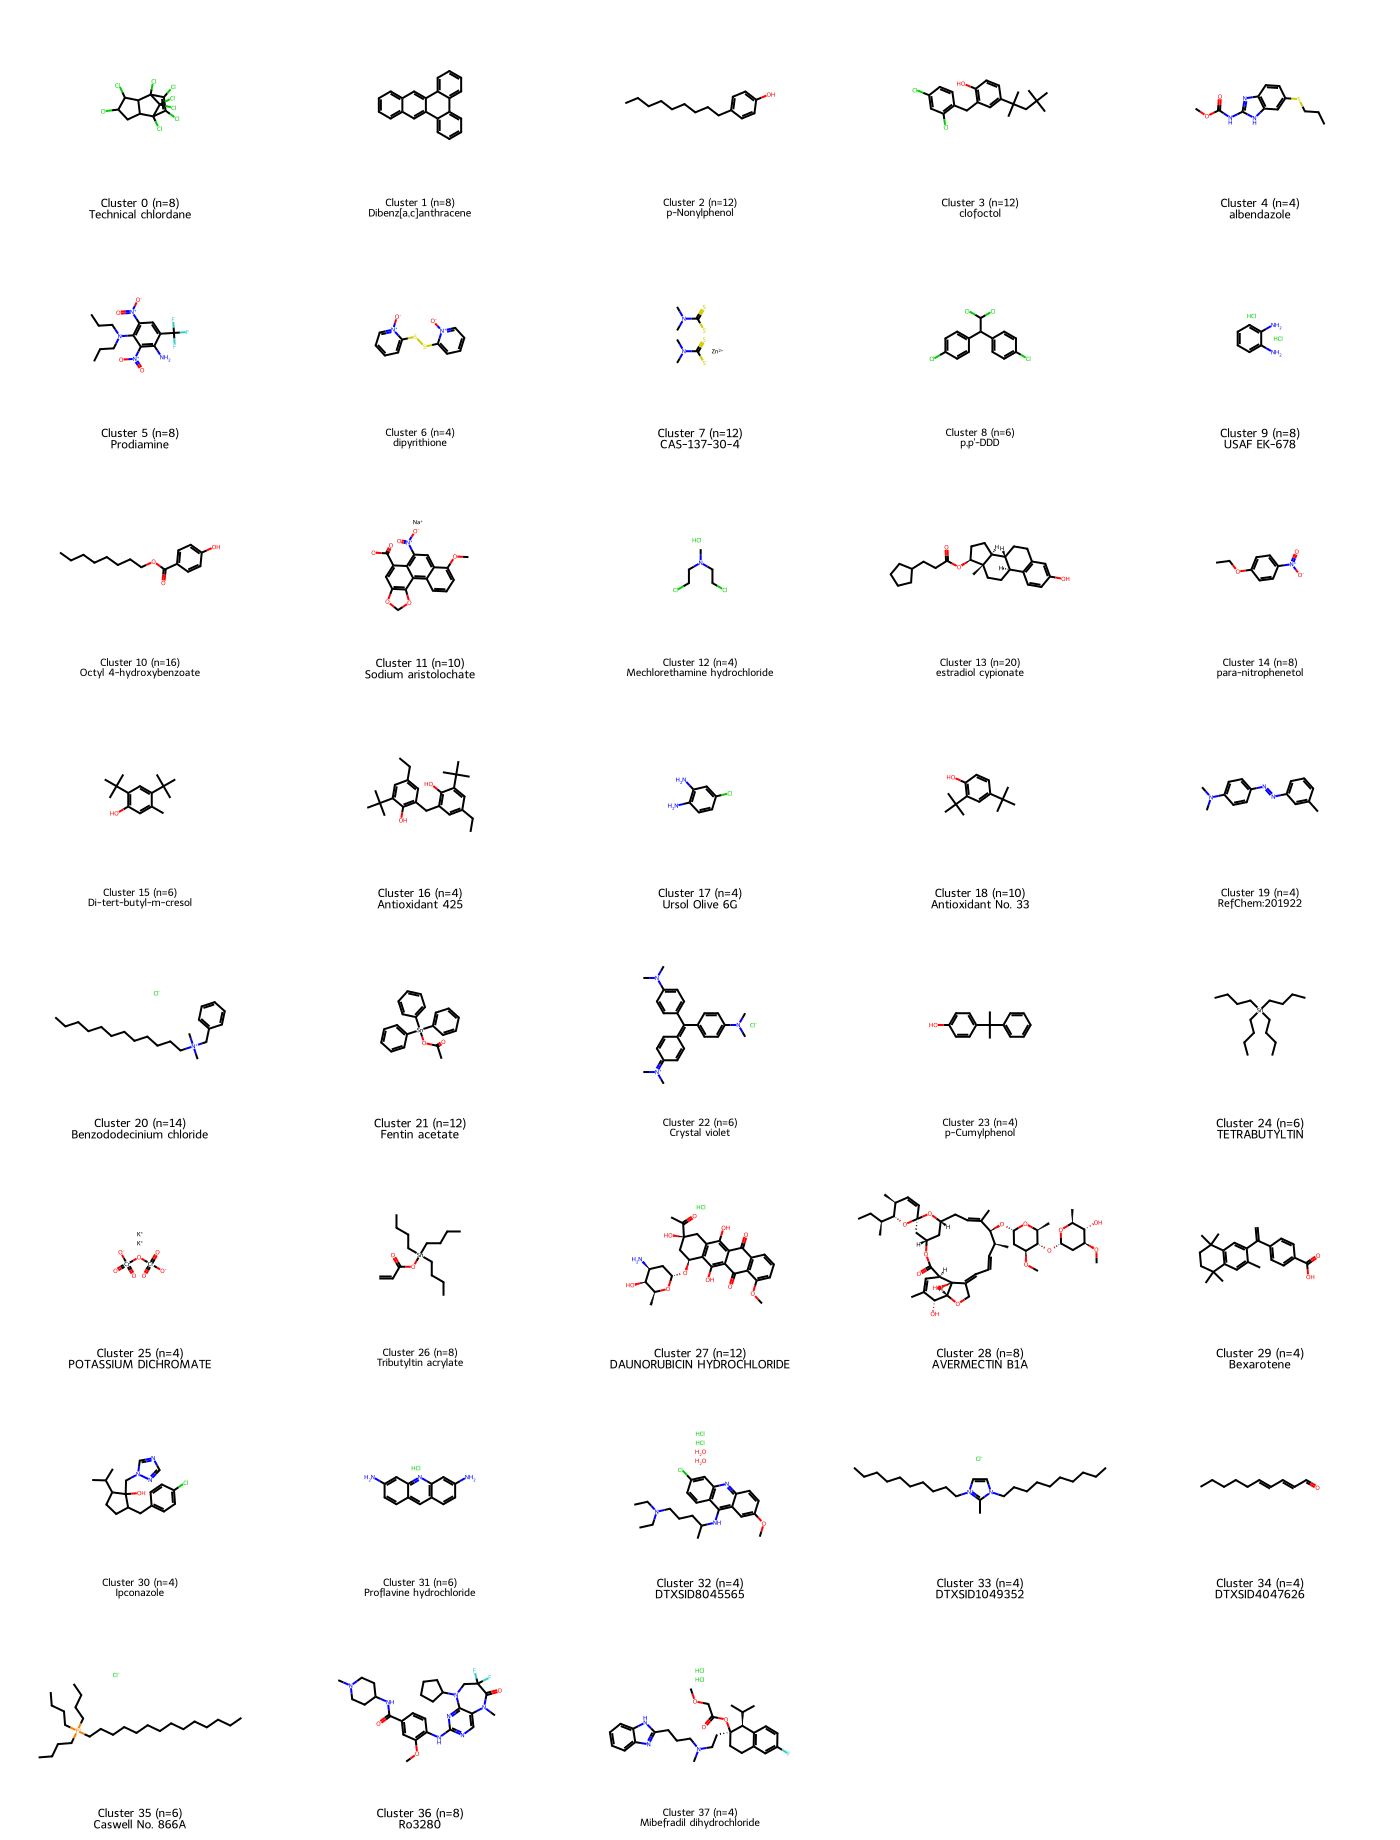

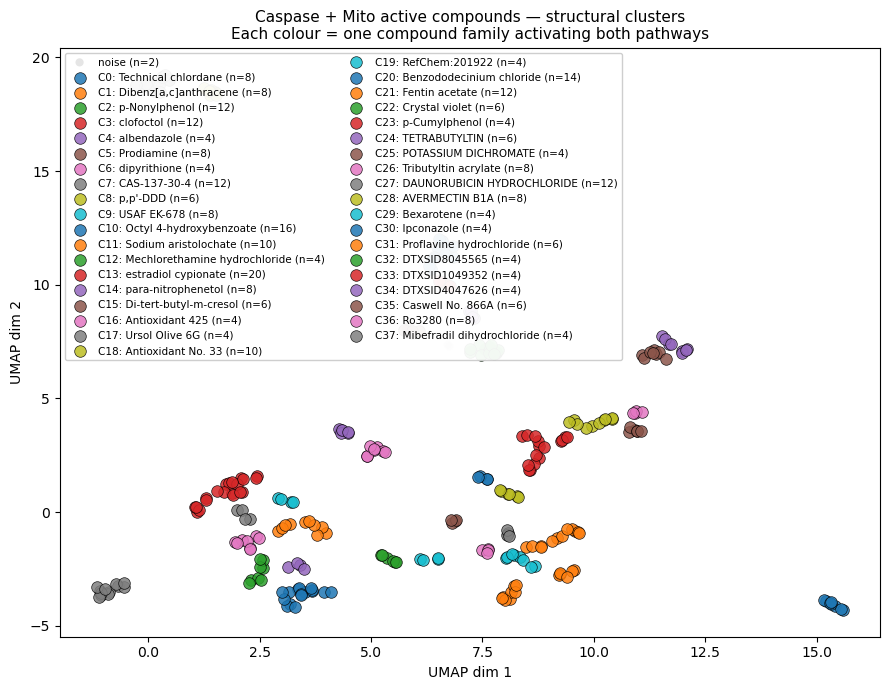

In [51]:
# Representative per cluster + PubChem name
reps_cm, legs_cm = [], []
cl_name_map_cm   = {}
print('Fetching names from PubChem...')

for cl in sorted(c for c in cm['cluster'].unique() if c != -1):
    sub  = cm[cm['cluster'] == cl].reset_index(drop=True)
    fps  = sub['fp'].tolist()
    avg  = [sum(DataStructs.BulkTanimotoSimilarity(fp, fps)) for fp in fps]
    rep  = sub.loc[int(np.argmax(avg))]
    cid  = int(rep['PUBCHEM_CID'])
    try:
        c_   = pcp.Compound.from_cid(cid)
        syns = c_.synonyms or []
        short = [s for s in syns if len(s) <= 30 and s[0].isalpha()]
        name  = short[0] if short else (syns[0][:28] if syns else str(cid))
    except Exception:
        name = str(cid)
    reps_cm.append(rep['mol'])
    legs_cm.append(f'Cluster {cl} (n={len(sub)})\n{name}')
    cl_name_map_cm[cl] = name
    print(f'  Cluster {cl:2d} (n={len(sub):3d})  {name}  [CID {cid}]')

# Draw reps
img = Draw.MolsToGridImage(reps_cm, molsPerRow=5, subImgSize=(280, 230),
                           legends=legs_cm, returnPNG=False)
display(img)

# UMAP coloured by cluster
fig, ax = plt.subplots(figsize=(9, 7))
cmap = plt.cm.tab10
noise_cm = cm[cm['cluster'] == -1]
ax.scatter(noise_cm['umap_x'], noise_cm['umap_y'], c='#cccccc',
           s=35, edgecolors='none', alpha=0.5, label=f'noise (n={len(noise_cm)})')
for cl in sorted(c for c in cm['cluster'].unique() if c != -1):
    sub = cm[cm['cluster'] == cl]
    ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 10)],
               s=70, edgecolors='black', linewidths=0.5, alpha=0.85,
               label=f'C{cl}: {cl_name_map_cm.get(cl, f"Cluster {cl}")} (n={len(sub)})')
ax.legend(loc='upper left', fontsize=7.5, framealpha=0.95, ncol=2)
ax.set_title('Caspase + Mito active compounds — structural clusters\n'
             'Each colour = one compound family activating both pathways', fontsize=11)
ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
plt.tight_layout()
plt.show()

Drawing 5 panels across 1 cluster(s) (includes 1 core panel per cluster)


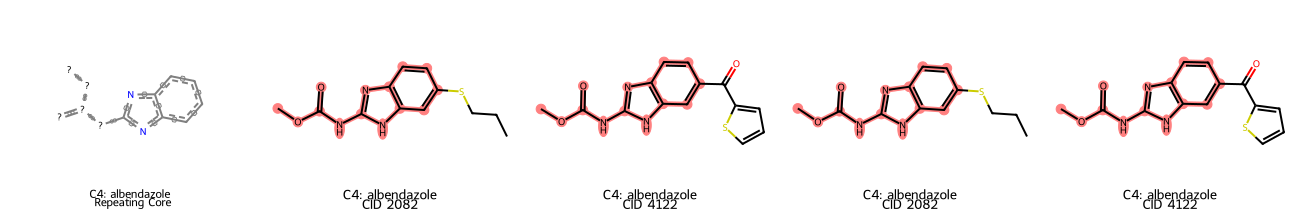

In [62]:
from rdkit.Chem import Draw, rdFMCS
from rdkit import Chem
from IPython.display import display

DATASET         = cm               # cm (Section 4), h (Section 2), h27 (Section 3)
NAME_MAP        = cl_name_map_cm   # cl_name_map_cm (Sec 4), cl_name_map (Sec 2/3)
CLUSTERS        = [4]             # which clusters to show — None = show ALL
MOLS_PER_ROW    = 5
IMG_SIZE        = (260, 220)
MAX_PER_CLUSTER = 10            # max molecules drawn per cluster

cluster_ids = sorted(c for c in DATASET['cluster'].unique() if c != -1)
if CLUSTERS is not None:
    cluster_ids = [c for c in cluster_ids if c in CLUSTERS]

mols, legends, highlight_atoms = [], [], []

for cl in cluster_ids:
    sub   = DATASET[DATASET['cluster'] == cl].reset_index(drop=True)
    name  = NAME_MAP.get(cl, f'Cluster {cl}')
    shown = sub.head(MAX_PER_CLUSTER)

    cluster_mols = [row['mol'] for _, row in shown.iterrows()]

    # --- Compute MCS for the cluster ---
    core_mol = None
    if len(cluster_mols) >= 2:
        mcs = rdFMCS.FindMCS(
            cluster_mols,
            ringMatchesRingOnly=True,
            completeRingsOnly=True,
            timeout=10,
        )
        if mcs and mcs.numAtoms > 0:
            core_mol = Chem.MolFromSmarts(mcs.smartsString)

    # Insert the repeating core as the first panel
    if core_mol is not None:
        mols.append(core_mol)
        legends.append(f'C{cl}: {name}\n★ Repeating Core ★')
        highlight_atoms.append([])          # no highlight on the core itself

    # Individual molecules with MCS atoms highlighted
    for _, row in shown.iterrows():
        cid = int(row['PUBCHEM_CID'])
        mol = row['mol']
        mols.append(mol)
        legends.append(f'C{cl}: {name}\nCID {cid}')

        if core_mol is not None:
            match = mol.GetSubstructMatch(core_mol)
            highlight_atoms.append(list(match))
        else:
            highlight_atoms.append([])

print(f"Drawing {len(mols)} panels across {len(cluster_ids)} cluster(s) "
      f"(includes 1 core panel per cluster)")

img = Draw.MolsToGridImage(
    mols,
    molsPerRow       = MOLS_PER_ROW,
    subImgSize       = IMG_SIZE,
    legends          = legends,
    highlightAtomLists = highlight_atoms,
    returnPNG        = False,
)
display(img)

189 caspase+mito active compounds


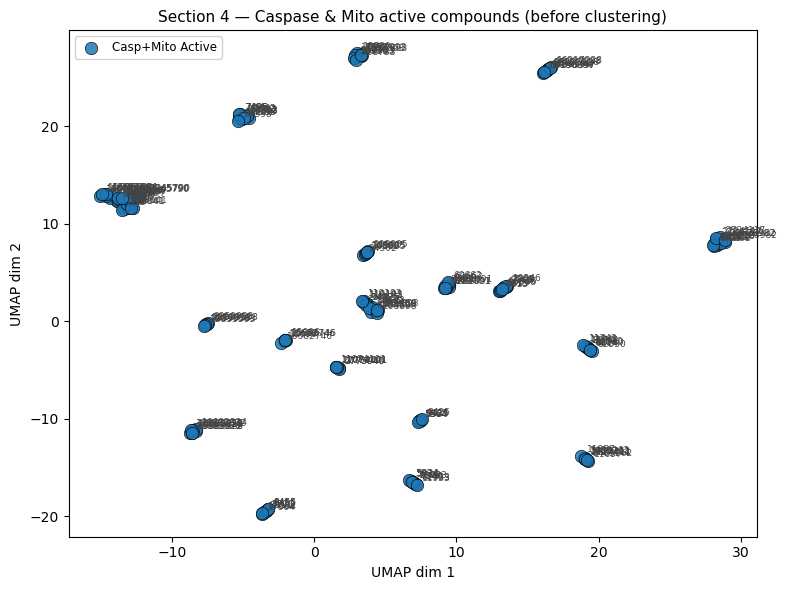

DBSCAN: 22 clusters, 0 noise


In [67]:
import pubchempy as pcp
from rdkit.Chem import Draw
from IPython.display import display

# Load
cm = pd.read_csv(BASE + 'results/casepase_mito_comparisons/case1_caspase_active_mito_active_viability_active.csv',
                 usecols=['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES'], low_memory=False)
cm['mol'] = cm['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
    lambda s: Chem.MolFromSmiles(s) if pd.notna(s) else None)
cm = cm[cm['mol'].notna()].reset_index(drop=True)
cm['fp'], fp_matrix_4 = to_fp_matrix(cm['mol'].tolist())
print(f'{len(cm)} caspase+mito active compounds')

# UMAP + DBSCAN
emb_4 = plot_umap(fp_matrix_4, labels=['Casp+Mito Active'] * len(cm),
                  title='Section 4 — Caspase & Mito active compounds (before clustering)',
                  annotate=cm['PUBCHEM_CID'].astype(int))
cm['umap_x'], cm['umap_y'] = emb_4[:, 0], emb_4[:, 1]

db_cm = DBSCAN(eps=0.4, min_samples=3).fit(emb_4)
cm['cluster'] = db_cm.labels_
n_cl_cm = len(set(db_cm.labels_)) - (1 if -1 in db_cm.labels_ else 0)
print(f'DBSCAN: {n_cl_cm} clusters, {(db_cm.labels_==-1).sum()} noise')

Fetching names from PubChem...
  Cluster  0 (n= 18)  o-Phthalaldehyde  [CID 4807]
  Cluster  1 (n= 12)  p-Nonylphenol  [CID 1752]
  Cluster  2 (n= 12)  ORYZALIN  [CID 29393]
  Cluster  3 (n=  6)  triclosan  [CID 5564]
  Cluster  4 (n=  9)  o-Aminoazotoluene  [CID 7340]
  Cluster  5 (n=  9)  Di-tert-butyl-m-cresol  [CID 10346]
  Cluster  6 (n=  9)  Antioxidant No. 33  [CID 7311]
  Cluster  7 (n= 12)  Myristalkonium chloride  [CID 8755]
  Cluster  8 (n=  9)  p-tert-Octylphenol  [CID 8814]
  Cluster  9 (n=  9)  estradiol cypionate  [CID 9403]
  Cluster 10 (n=  9)  Fentin acetate  [CID 16682804]
  Cluster 11 (n=  9)  Crystal violet  [CID 11057]
  Cluster 12 (n=  6)  Dodecyl gallate  [CID 14425]
  Cluster 13 (n=  9)  Hydroxytamoxifen  [CID 449459]
  Cluster 14 (n=  6)  Tributyltin chloride  [CID 15096]
  Cluster 15 (n=  6)  POTASSIUM DICHROMATE  [CID 24502]
  Cluster 16 (n=  6)  Fludioxonil  [CID 86398]
  Cluster 17 (n=  3)  Tetraoctylammonium bromide  [CID 2734117]
  Cluster 18 (n=  6)  DT

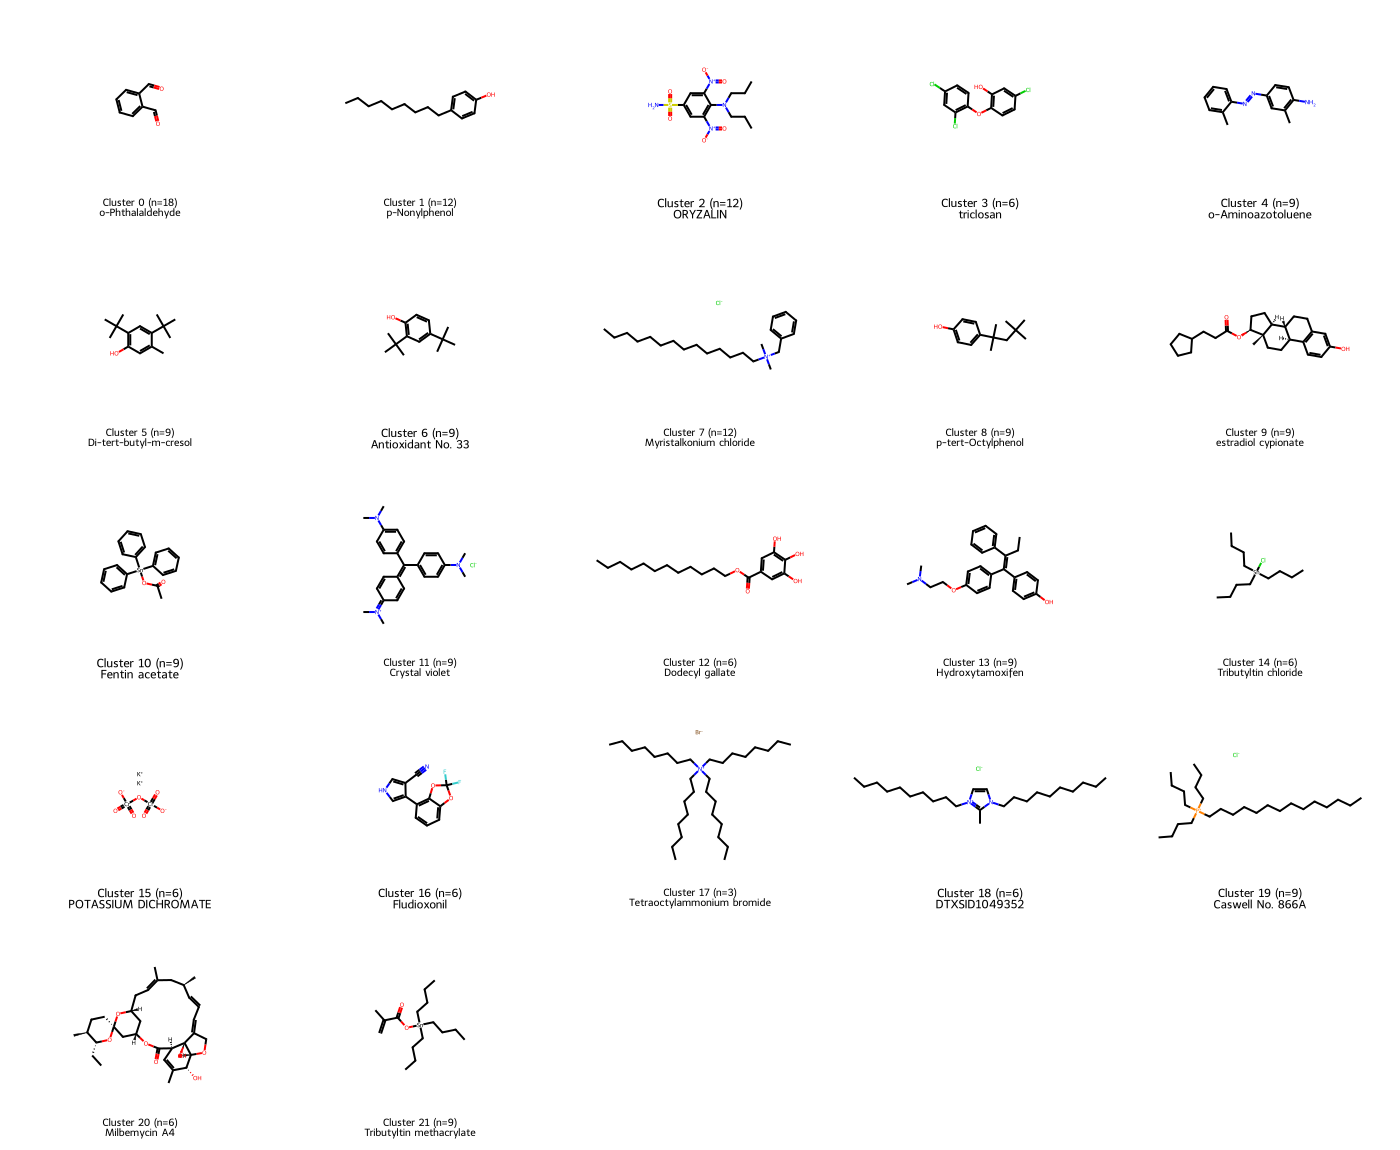

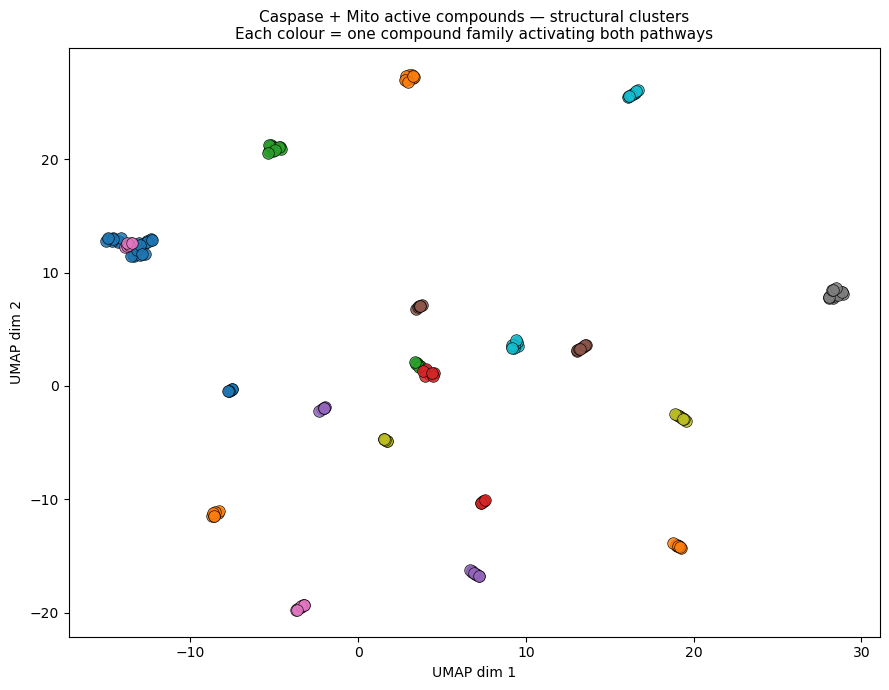

In [68]:
# Representative per cluster + PubChem name
reps_cm, legs_cm = [], []
cl_name_map_cm   = {}
print('Fetching names from PubChem...')

for cl in sorted(c for c in cm['cluster'].unique() if c != -1):
    sub  = cm[cm['cluster'] == cl].reset_index(drop=True)
    fps  = sub['fp'].tolist()
    avg  = [sum(DataStructs.BulkTanimotoSimilarity(fp, fps)) for fp in fps]
    rep  = sub.loc[int(np.argmax(avg))]
    cid  = int(rep['PUBCHEM_CID'])
    try:
        c_   = pcp.Compound.from_cid(cid)
        syns = c_.synonyms or []
        short = [s for s in syns if len(s) <= 30 and s[0].isalpha()]
        name  = short[0] if short else (syns[0][:28] if syns else str(cid))
    except Exception:
        name = str(cid)
    reps_cm.append(rep['mol'])
    legs_cm.append(f'Cluster {cl} (n={len(sub)})\n{name}')
    cl_name_map_cm[cl] = name
    print(f'  Cluster {cl:2d} (n={len(sub):3d})  {name}  [CID {cid}]')

# Draw reps
img = Draw.MolsToGridImage(reps_cm, molsPerRow=5, subImgSize=(280, 230),
                           legends=legs_cm, returnPNG=False)
display(img)

# UMAP coloured by cluster
fig, ax = plt.subplots(figsize=(9, 7))
cmap = plt.cm.tab10
noise_cm = cm[cm['cluster'] == -1]
ax.scatter(noise_cm['umap_x'], noise_cm['umap_y'], c='#cccccc',
           s=35, edgecolors='none', alpha=0.5, label=f'noise (n={len(noise_cm)})')
for cl in sorted(c for c in cm['cluster'].unique() if c != -1):
    sub = cm[cm['cluster'] == cl]
    ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 10)],
               s=70, edgecolors='black', linewidths=0.5, alpha=0.85,
               label=f'C{cl}: {cl_name_map_cm.get(cl, f"Cluster {cl}")} (n={len(sub)})')
#ax.legend(loc='upper left', fontsize=7.5, framealpha=0.95, ncol=2)
ax.set_title('Caspase + Mito active compounds — structural clusters\n'
             'Each colour = one compound family activating both pathways', fontsize=11)
ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
plt.tight_layout()
plt.show()